# 06. GP versus standard machine-learning models

**Purpose.** Check whether the GP is needed at all. Four common regression
models (support vector regression, random forest, XGBoost and a small neural
network) are trained on exactly the same inputs and the same 10 folds as the
final GP, and all five are scored the same way.

**What this notebook produces** (in `Output_Data/ml_baselines/`)

* `all_model_results.csv`: pooled train and test metrics for every model and property.
* A comparison bar chart of test R².
* Per-model parity and fold plots in `<property>/<model>/` (saved to disk only).

**Things to keep in mind**

* The ML models use the same two inputs as the GP, `[molecular weight, GC
  estimate]`. For method-2 properties (Pc and ΔHvap) they learn the GC error
  from molecular weight only, just like the GP.
* Only the GP gives an uncertainty. The interval columns of the other models are zero.
* This step refits every GP, so a full run takes a while (log P is the slowest).

## 1. Environment and setup

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder that contains src/gcgp) and make the
# shared code importable. This works whether Jupyter starts in notebooks/ or
# in the repository root.
repoRoot = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gcgp").is_dir())
sys.path.insert(0, str(repoRoot / "src"))

import pandas as pd

from gcgp.settings import checkCuratedData, describeSetup, outputFolder, setGlobalSeed
from gcgp.properties import PROPERTIES, PROPERTY_ORDER, loadPropertyData
from gcgp.finalConfig import RUN_NAMES, getGpConfig, getSettings
from gcgp.mlBaselines import MODEL_NAMES, runModelComparisonCv
from gcgp.plotting import plotModelComparison

setGlobalSeed()
outputDir = outputFolder("ml_baselines")
pd.set_option("display.precision", 3)
checkCuratedData()
print(describeSetup())

Run mode      : FULL
Input folder  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Input_Data
Output folder : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data
Curated data  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/curated_data
GP workers    : 1 (set GCGP_N_WORKERS to fit restarts in parallel)
Global seed   : 42


## 2. Train and score all models

Each property is read from its curated dataset in `Output_Data/curated_data/`,
and the GP uses that property's final settings from notebook 04.

A GP or ML fold that fails numerically (for example a failed Cholesky
decomposition) is dropped from the pooled metrics with a message, and the run
continues. GP restarts are checkpointed in `Output_Data/checkpoints/`, so an
interrupted run resumes where it stopped. Figures are saved to
disk rather than shown, since there are five models for each of seven properties.

In [2]:
allSummaries = []
for code in PROPERTY_ORDER:
    info = PROPERTIES[code]
    settings = getSettings(code)
    runName = RUN_NAMES[code]
    summary = runModelComparisonCv(
        runName, loadPropertyData(code), info["featureCols"], info["targetCol"], getGpConfig(code),
        settings["retrainGp"], outputDir, info["xLabel"], info["yLabel"], code,
        modelNames=MODEL_NAMES, showPlots=False)
    allSummaries.append(summary)
    print(f"{runName}: done")

resultsDf = pd.concat(allSummaries, ignore_index=True)
resultsDf.to_csv(outputDir / "all_model_results.csv", index=False)

Tb: done
Tm: done
Pc: done
Vc: done
Tc: done
Hvap: done
LogP: done


## 3. Results

### 3.1 Pooled test metrics

`Overfitting_dR2` is train R² minus test R². A large value (the random forest is
the usual example) means the model memorises the training molecules.

In [3]:
resultsDf[["Property", "Model", "Overall_Train_R2", "Overall_Test_R2", "Overfitting_dR2",
           "Overall_Test_RMSE", "Overall_Test_MAE"]]

,Property,Model,Overall_Train_R2,Overall_Test_R2,Overfitting_dR2,Overall_Test_RMSE,Overall_Test_MAE
0,Tb,GP,0.852,0.848,0.003,26.566,20.780
1,Tb,SVR,0.840,0.835,0.006,27.747,21.363
2,Tb,RandomForest,0.970,0.847,0.123,26.650,19.674
3,Tb,XGBoost,0.929,0.815,0.114,29.316,21.638
4,Tb,NeuralNetwork,0.848,0.836,0.012,27.629,21.124
5,Tm,GP,0.629,0.616,0.013,55.000,43.589
6,Tm,SVR,0.594,0.584,0.010,57.236,44.856
7,Tm,RandomForest,0.924,0.610,0.313,55.404,42.929
8,Tm,XGBoost,0.722,0.548,0.174,59.666,46.810
9,Tm,NeuralNetwork,0.608,0.603,0.005,55.899,44.297


### 3.2 Test R² by model

Each group of bars is one property. Bars of similar height mean the GP and the simpler
models predict about equally well on these two inputs.

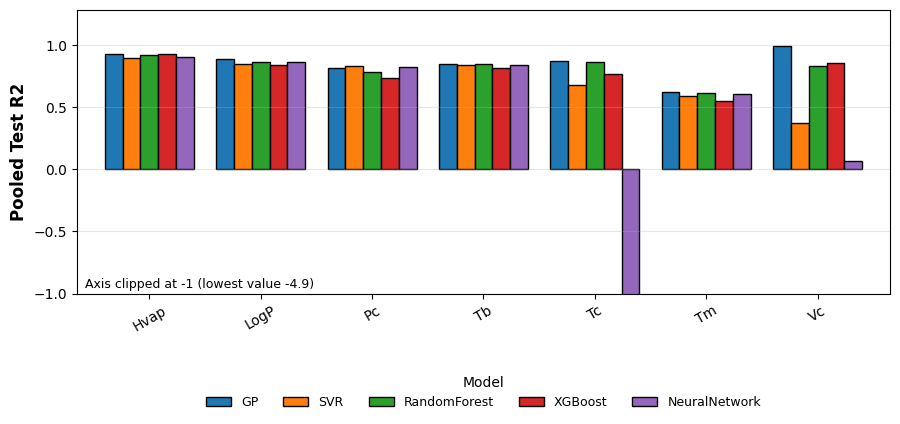

In [4]:
plotModelComparison(resultsDf, metric="Overall_Test_R2", savePath=outputDir / "model_comparison_test_R2.png")

### 3.3 Best model per property

In [5]:
best = resultsDf.loc[resultsDf.groupby("Property")["Overall_Test_R2"].idxmax()]
best[["Property", "Model", "Overall_Test_R2", "Overall_Test_RMSE"]].reset_index(drop=True)

,Property,Model,Overall_Test_R2,Overall_Test_RMSE
0,Hvap,XGBoost,0.925,1.921
1,LogP,GP,0.883,0.675
2,Pc,SVR,0.826,5.303
3,Tb,GP,0.848,26.566
4,Tc,GP,0.866,32.183
5,Tm,GP,0.616,55.000
6,Vc,GP,0.987,18.116


## 4. Summary of the results

Written from the results table above and saved as
`Output_Data/ml_baselines/results_summary.md`.

In [6]:
from gcgp.narrative import describeMlComparison, showAndSave

showAndSave(describeMlComparison(resultsDf), outputDir / "results_summary.md");

## GP versus standard machine-learning models: results

- **Tb**: GP test R² = 0.848, RMSE = 26.57 K; best model is GP (test R² = 0.848, RMSE = 26.57 K).
- **Tm**: GP test R² = 0.616, RMSE = 55.00 K; best model is GP (test R² = 0.616, RMSE = 55.00 K).
- **Pc**: GP test R² = 0.809, RMSE = 5.55 bar; best model is SVR (test R² = 0.826, RMSE = 5.30 bar).
- **Vc**: GP test R² = 0.987, RMSE = 18.12 cm³/mol; best model is GP (test R² = 0.987, RMSE = 18.12 cm³/mol).
- **Tc**: GP test R² = 0.866, RMSE = 32.18 K; best model is GP (test R² = 0.866, RMSE = 32.18 K).
- **ΔHvap**: GP test R² = 0.922, RMSE = 1.96 kJ/mol; best model is XGBoost (test R² = 0.925, RMSE = 1.92 kJ/mol).
- **log P**: GP test R² = 0.883, RMSE = 0.675; best model is GP (test R² = 0.883, RMSE = 0.675).

The GP has the highest test R² for 5 of 7 properties.


## 5. Ensemble of the four ML models

**Idea.** Combine SVR, random forest, XGBoost and the neural network into one
model that is built the same way for every property.

* **Prediction:** the equal-weight mean of the four models. There are no
  per-property weights or tuning, so the recipe does not change between properties.
* **Uncertainty:** the four models disagree more on molecules that are far from
  the training data. The standard deviation across the four predictions
  (the disagreement) is the raw uncertainty signal.
* **Calibration:** disagreement alone is too small, because the models are similar.
  Inside each training fold the four models are refitted on 5 inner folds. The
  out-of-fold errors, divided by (disagreement + a small constant), give one
  multiplier `q` chosen so that 95% of those errors fall inside the interval.
  The interval for a new molecule is `q * (disagreement + constant)`. Only
  training data are used, so the test molecules do not influence `q`.

The GP is not a member of the ensemble. It stays in the tables as the reference
model, since it is the only other model with an uncertainty. The ensemble uses
exactly the same inputs and 10 folds as every other model above. Results go to
`Output_Data/ml_baselines/<property>/Ensemble/`.

In [7]:
from gcgp.mlBaselines import ENSEMBLE_MEMBERS

print("Ensemble members:", ", ".join(ENSEMBLE_MEMBERS))

ensembleSummaries = []
for code in PROPERTY_ORDER:
    info = PROPERTIES[code]
    settings = getSettings(code)
    runName = RUN_NAMES[code]
    summary = runModelComparisonCv(
        runName, loadPropertyData(code), info["featureCols"], info["targetCol"], getGpConfig(code),
        settings["retrainGp"], outputDir, info["xLabel"], info["yLabel"], code,
        modelNames=["Ensemble"], showPlots=False)
    ensembleSummaries.append(summary)
    print(f"{runName}: ensemble done")

ensembleDf = pd.concat(ensembleSummaries, ignore_index=True)
ensembleDf.to_csv(outputDir / "ensemble_results.csv", index=False)

# All six models in one table, for the tables and the bar chart below.
combinedDf = pd.concat([resultsDf, ensembleDf], ignore_index=True)
combinedDf.to_csv(outputDir / "all_model_results_with_ensemble.csv", index=False)

Ensemble members: SVR, RandomForest, XGBoost, NeuralNetwork
Tb: ensemble done
Tm: ensemble done
Pc: ensemble done
Vc: ensemble done
Tc: ensemble done
Hvap: ensemble done
LogP: ensemble done


### 5.1 Ensemble accuracy

Test R² of every model. `Ensemble_minus_best_single` is the ensemble minus the best of
the four single ML models, so a value near zero or above means averaging did not hurt.

In [8]:
r2Table = combinedDf.pivot(index="Property", columns="Model", values="Overall_Test_R2")
r2Table = r2Table.loc[[RUN_NAMES[c] for c in PROPERTY_ORDER], ["GP", *ENSEMBLE_MEMBERS, "Ensemble"]]
r2Table["Ensemble_minus_best_single"] = r2Table["Ensemble"] - r2Table[ENSEMBLE_MEMBERS].max(axis=1)
r2Table["Ensemble_minus_GP"] = r2Table["Ensemble"] - r2Table["GP"]
r2Table

Model,GP,SVR,RandomForest,XGBoost,NeuralNetwork,Ensemble,Ensemble_minus_best_single,Ensemble_minus_GP
Property,,,,,,,,
Tb,0.848,0.835,0.847,0.815,0.836,0.858,0.011,0.010
Tm,0.616,0.584,0.610,0.548,0.603,0.630,0.020,0.014
Pc,0.809,0.826,0.783,0.730,0.824,0.821,-0.005,0.012
Vc,0.987,0.370,0.831,0.850,0.062,0.937,0.087,-0.050
Tc,0.866,0.672,0.862,0.768,-4.912,0.470,-0.392,-0.396
Hvap,0.922,0.893,0.916,0.925,0.899,0.928,0.003,0.006
LogP,0.883,0.842,0.860,0.839,0.865,0.870,0.005,-0.013


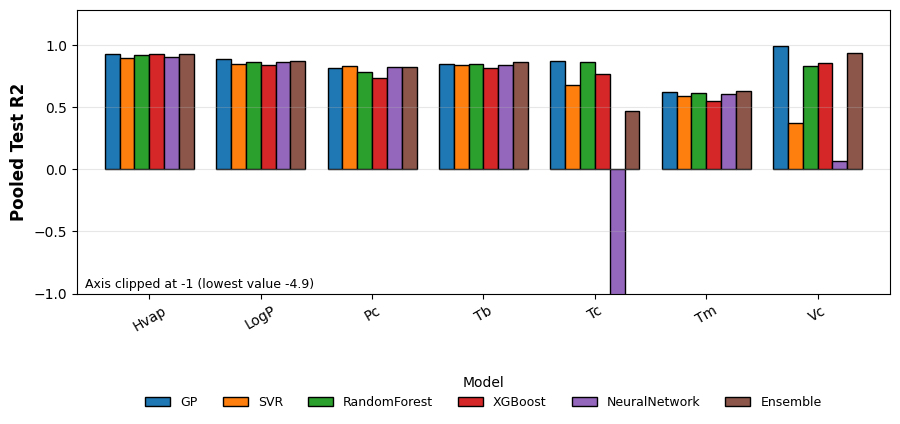

In [9]:
plotModelComparison(combinedDf, metric="Overall_Test_R2",
                    savePath=outputDir / "model_comparison_test_R2_with_ensemble.png")

### 5.2 Ensemble uncertainty

For the held-out (test) molecules of each property, compared with the GP:

* `Coverage_pct`: percent of test molecules whose true value lies inside the 95%
  interval. The target is 95.
* `Halfwidth_over_RMSE`: mean interval half-width divided by the test RMSE. It has no
  units, so it can be compared across properties. A narrower interval at the same
  coverage is better.
* `Spearman_err_vs_width`: rank correlation between each molecule's absolute error and
  its interval half-width. A value near 0 means the interval does not say which
  predictions are worse; a higher value means it does.

In [10]:
from gcgp.metrics import calculateMetrics


def intervalQuality(code, modelName):
    # Test-set coverage, relative width and error-versus-width rank correlation of one model.
    info, runName = PROPERTIES[code], RUN_NAMES[code]
    path = outputDir / runName / modelName / f"{runName}_{modelName}_predictions.csv"
    test = pd.read_csv(path).query("Set == 'Test'")
    error = (test[info["xLabel"]] - test[info["yLabel"]]).abs()
    width = test["95CI"]
    rmse = calculateMetrics(test[info["xLabel"]], test[info["yLabel"]])["RMSE"]
    return {"Property": runName, "Model": modelName,
            "Coverage_pct": 100 * (error <= width).mean(),
            "Halfwidth_over_RMSE": width.mean() / rmse,
            "Spearman_err_vs_width": error.corr(width, method="spearman")}


uncertaintyDf = pd.DataFrame([intervalQuality(code, model)
                              for code in PROPERTY_ORDER for model in ["GP", "Ensemble"]])
uncertaintyDf.to_csv(outputDir / "ensemble_uncertainty_quality.csv", index=False)
uncertaintyDf.pivot(index="Property", columns="Model")[
    ["Coverage_pct", "Halfwidth_over_RMSE", "Spearman_err_vs_width"]
].loc[[RUN_NAMES[c] for c in PROPERTY_ORDER]]

Coverage_pct         Halfwidth_over_RMSE         \
Model        Ensemble      GP            Ensemble     GP   
Property                                                   
Tb             94.582  93.792               2.148  1.961   
Tm             95.595  94.671               2.231  1.961   
Pc             98.667  89.333               3.995  1.789   
Vc             97.101  92.754               1.831  1.643   
Tc             95.714  90.000               1.661  1.798   
Hvap           98.571  92.857               2.485  1.893   
LogP           95.064  94.191               1.813  1.709   

         Spearman_err_vs_width         
Model                 Ensemble     GP  
Property                               
Tb                       0.214 -0.064  
Tm                       0.095 -0.038  
Pc                       0.175 -0.164  
Vc                       0.435 -0.319  
Tc                       0.166 -0.178  
Hvap                     0.157  0.072  
LogP                     0.267  0.275

### 5.3 Is the ensemble the same across properties?

The spread of test R² across the seven properties for each model, and the mean
coverage. A model that "behaves the same way" for every property has a coverage
close to 95 for all of them (small standard deviation).

In [11]:
pd.DataFrame({
    "Mean_test_R2": r2Table[["GP", *ENSEMBLE_MEMBERS, "Ensemble"]].mean(),
    "Std_test_R2_across_properties": r2Table[["GP", *ENSEMBLE_MEMBERS, "Ensemble"]].std(),
}).join(uncertaintyDf.groupby("Model")["Coverage_pct"].agg(Mean_coverage_pct="mean",
                                                            Std_coverage_pct="std"))

,Mean_test_R2,Std_test_R2_across_properties,Mean_coverage_pct,Std_coverage_pct
Model,,,,
GP,0.847,0.117,92.514,2.070
SVR,0.717,0.188,NaN,NaN
RandomForest,0.816,0.099,NaN,NaN
XGBoost,0.782,0.121,NaN,NaN
NeuralNetwork,-0.118,2.134,NaN,NaN
Ensemble,0.788,0.173,96.471,1.659
